In [12]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

In [7]:
df=pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\Wisconsin\BreastCancer.csv",index_col=0)
X,y=df.drop('Class',axis=1),df['Class']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=.3,stratify=y)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


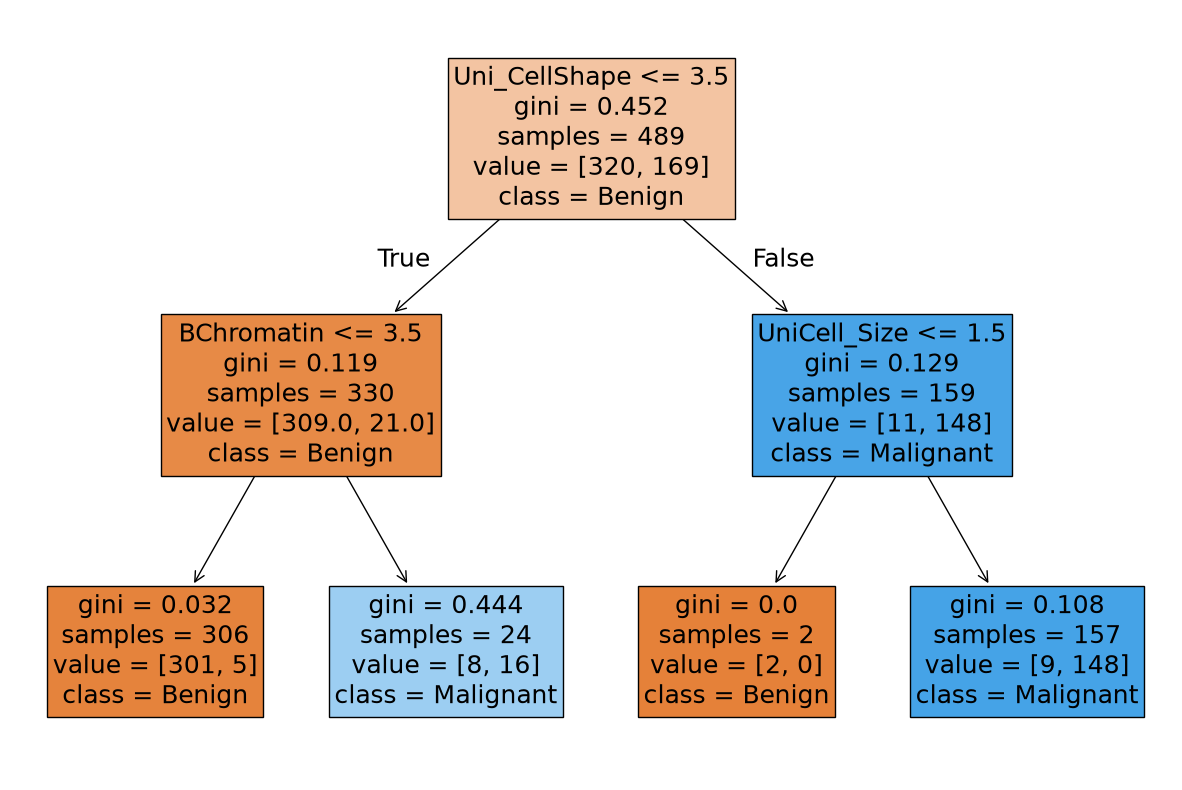

In [14]:
import matplotlib.pyplot as plt
dtc=DecisionTreeClassifier(random_state=26,max_depth=2)
dtc.fit(X_train,y_train)
plt.figure(figsize=(15,10))
plot_tree(dtc,feature_names=list(X.columns),
         class_names=['Benign','Malignant'], filled= True, fontsize = 18)
plt.show()

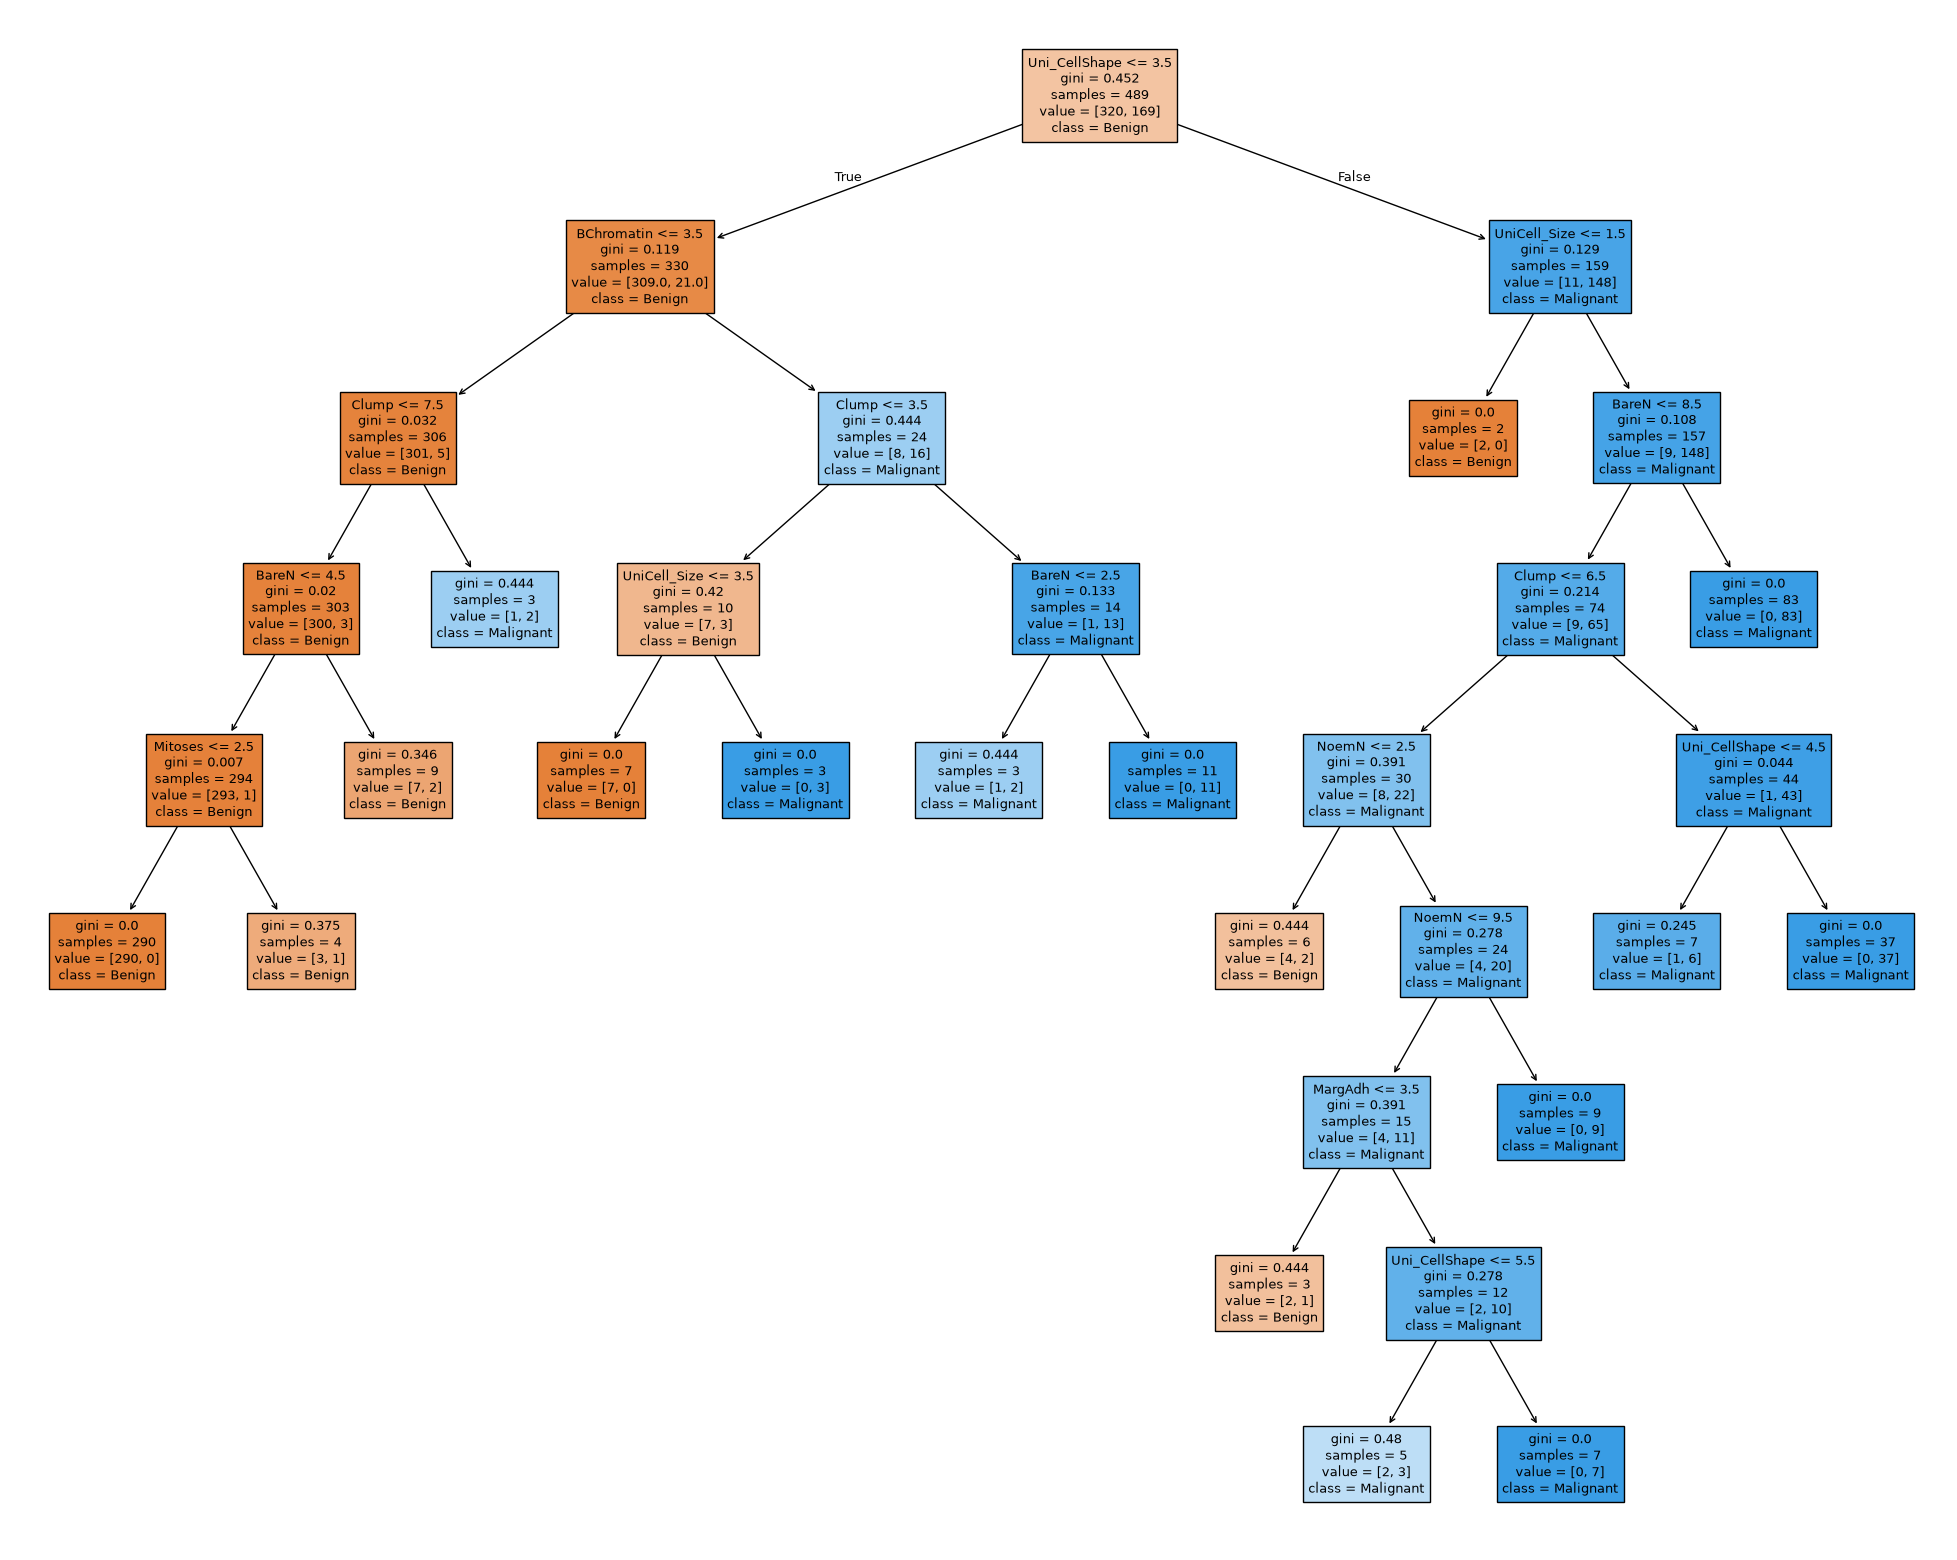

In [20]:
import matplotlib.pyplot as plt
dtc=DecisionTreeClassifier(random_state=26,min_samples_split=10)
dtc.fit(X_train,y_train)
plt.figure(figsize=(25,20))
plot_tree(dtc,feature_names=list(X.columns),
         class_names=['Benign','Malignant'], filled= True, fontsize = 9)
plt.show()

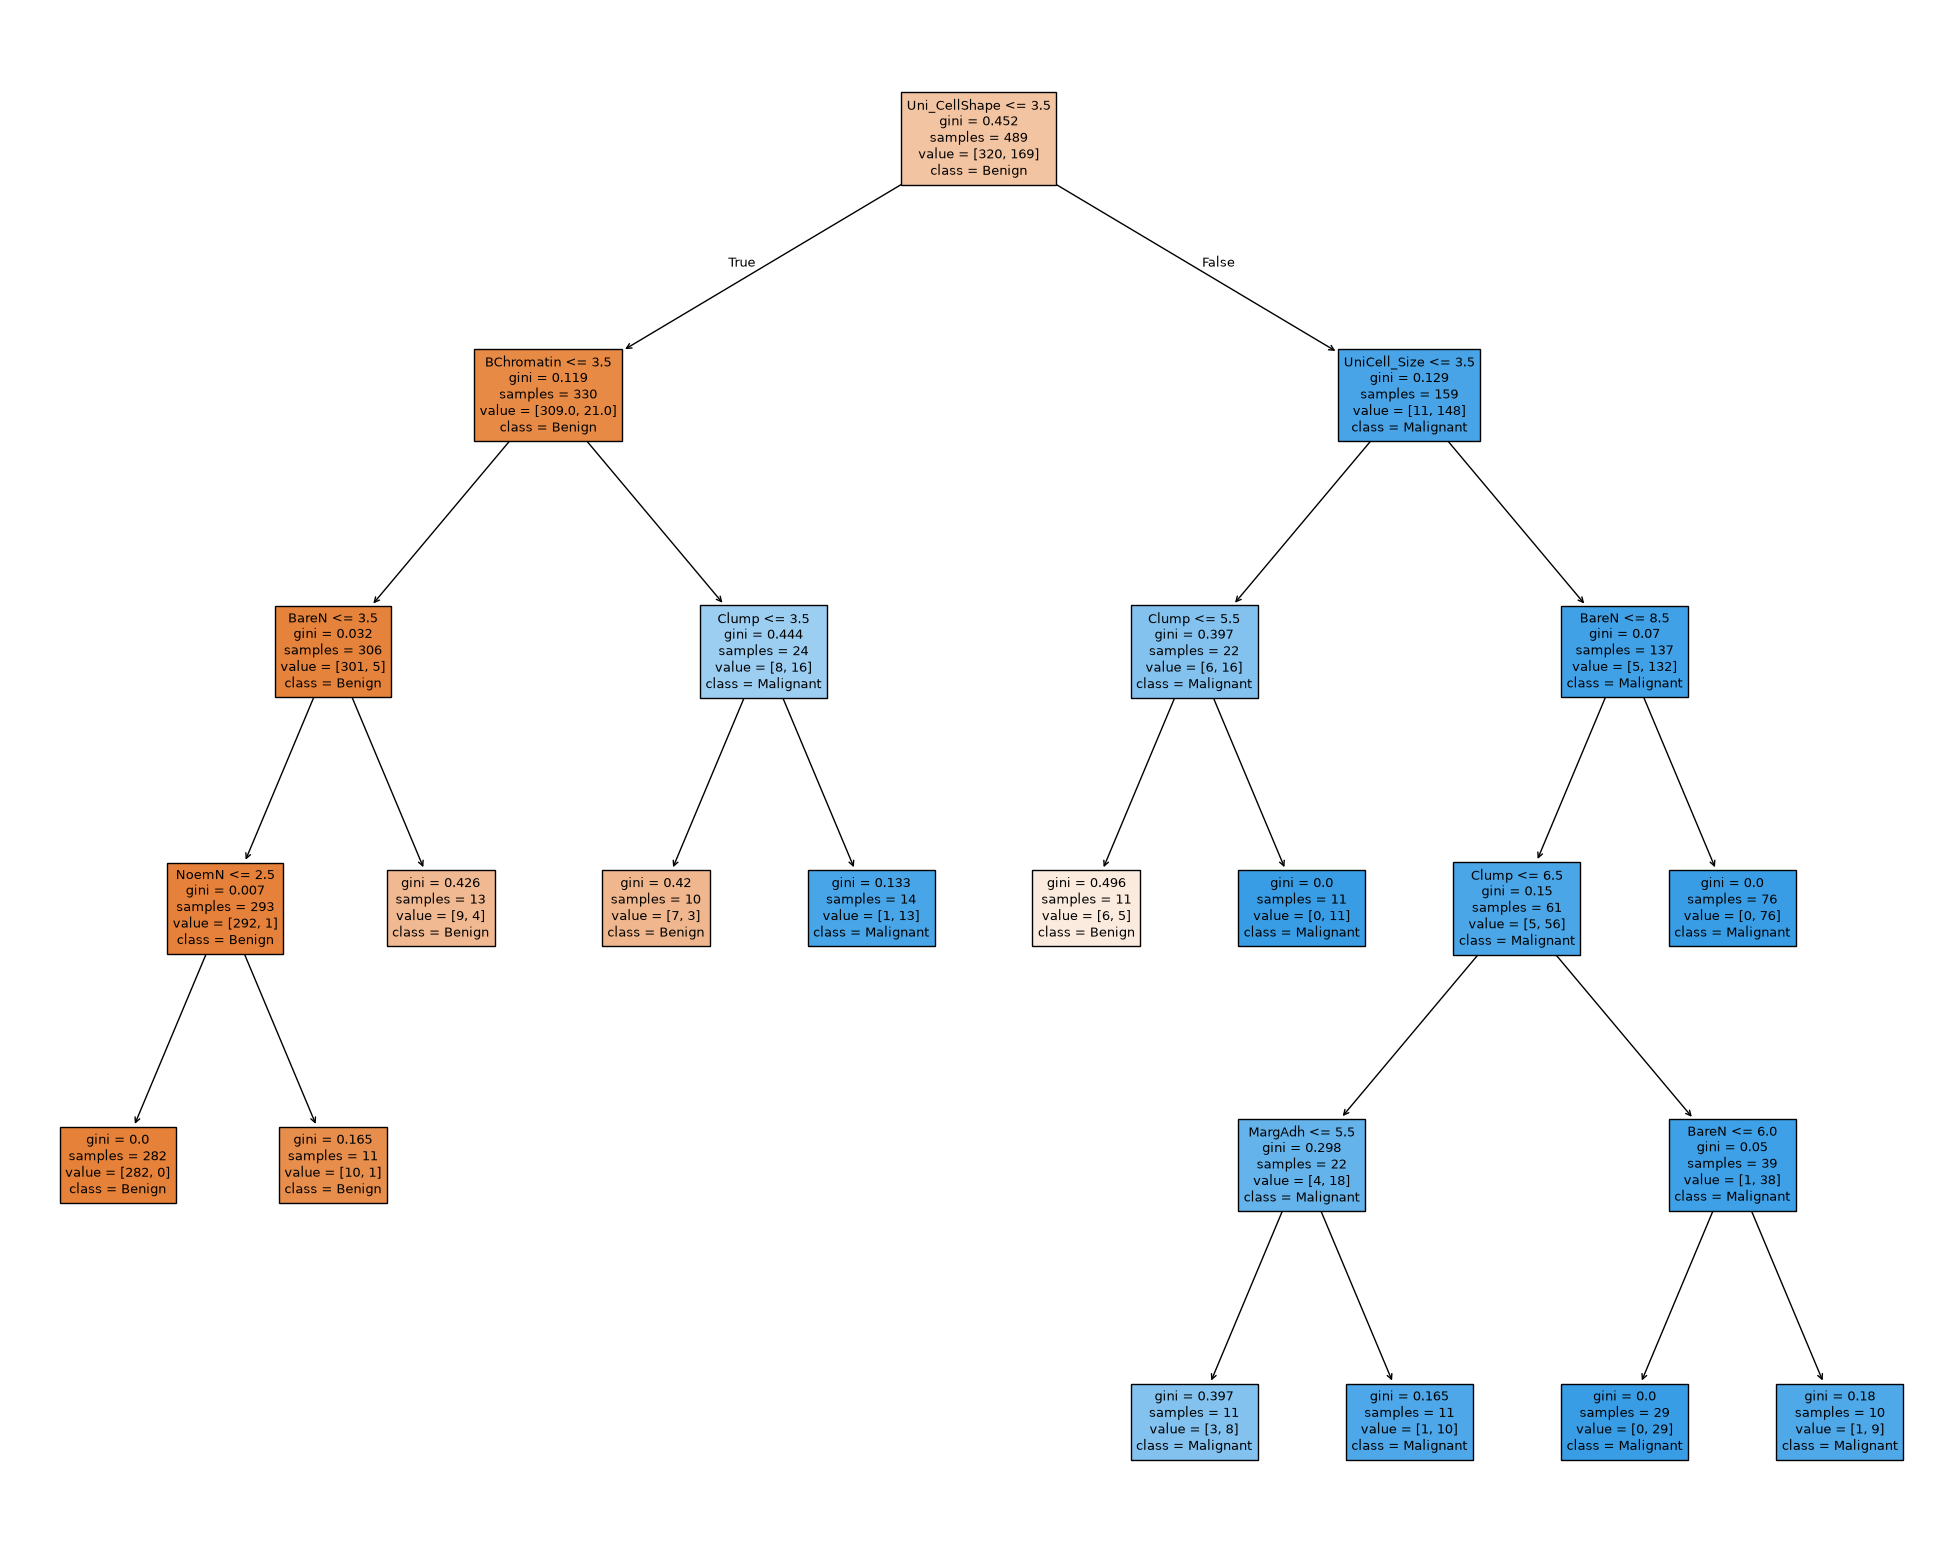

In [21]:
import matplotlib.pyplot as plt
dtc=DecisionTreeClassifier(random_state=26,min_samples_leaf=10)
dtc.fit(X_train,y_train)
plt.figure(figsize=(25,20))
plot_tree(dtc,feature_names=list(X.columns),
         class_names=['Benign','Malignant'], filled= True, fontsize = 9)
plt.show()

In [23]:
from sklearn.metrics import accuracy_score
depths = [None, 2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []
for d in depths:
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26, max_depth = d, min_samples_split= s, min_samples_leaf= f)
            dtc.fit(X_train, y_train)
            y_pred = dtc.predict(X_test)
            scores.append([d, s, f, accuracy_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns= ['depth','split','leaf','score'])
df_scores.sort_values('score', ascending = False, ignore_index= True)

,depth,split,leaf,score
0,NaN,10,1,0.957143
1,7.0,10,1,0.957143
2,NaN,2,1,0.947619
3,6.0,2,1,0.947619
4,7.0,2,1,0.947619
...,...,...,...,...
170,6.0,50,50,0.895238
171,7.0,10,50,0.895238
172,7.0,5,50,0.895238
173,7.0,20,50,0.895238


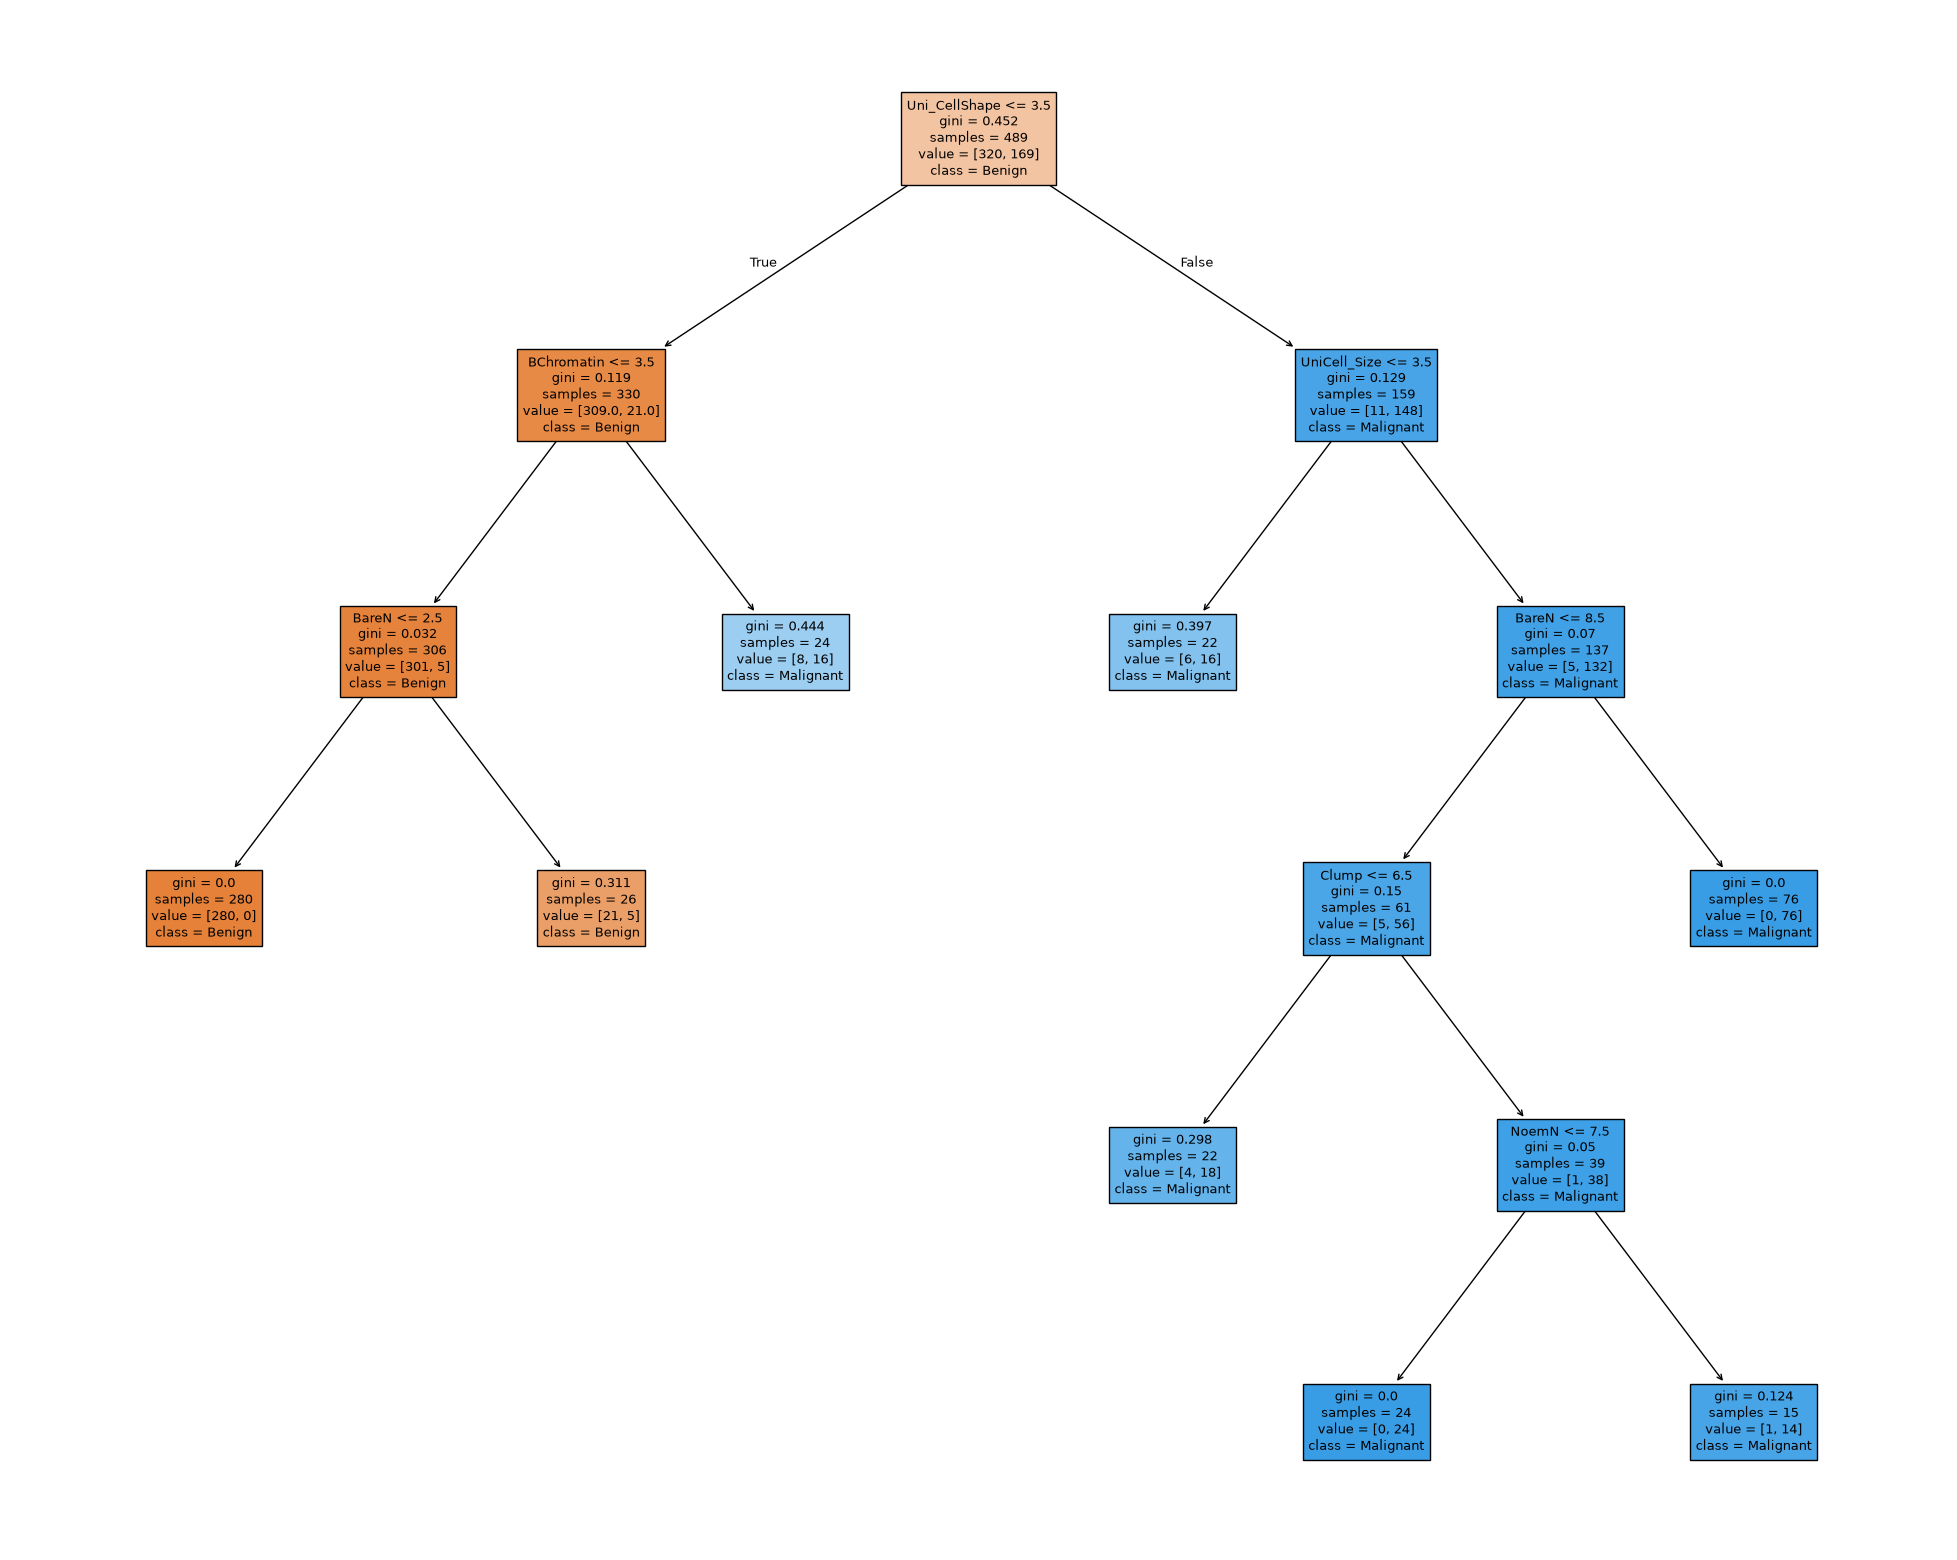

In [24]:
dtc=DecisionTreeClassifier(random_state=26,min_samples_leaf=15)
dtc.fit(X_train,y_train)
plt.figure(figsize=(25,20))
plot_tree(dtc,feature_names=list(X.columns),
         class_names=['Benign','Malignant'], filled= True, fontsize = 9)
plt.show()